# Gong & Simchi-Levi: 5 thực nghiệm cho bài trình bày 45 phút

Notebook tự chạy, không tải dữ liệu và không phụ thuộc mã trong thư mục lưu trữ.
Chọn **Run All** từ đầu. Mọi thiết lập nằm trong cell cấu hình.
Yêu cầu Python 3.10+ với NumPy, pandas, Matplotlib, SciPy và IPython.
Nếu thiếu thư viện, chạy `%pip install numpy pandas matplotlib scipy ipykernel`
trong một cell riêng rồi khởi động lại kernel. Không cần GPU.

| Phần | Nội dung | Phút trình bày |
|---|---|---|
| Recap | Lost-sales, phản hồi một phía, HQL và các arm dịch pha | 0–8 |
| TN1 | Lợi ích chu kỳ và đường học | 8–17 |
| TN2 | Running Set, chuyển arm, tồn kho dư | 17–23 |
| TN3 | Biến động, thiếu hàng và rủi ro đuôi | 23–29 |
| TN4 | Quy hoạch động trung tính và nhạy cảm rủi ro | 29–34 |
| TN5 | Chi phí vốn và giá trị chờ đặt hàng | 34–40 |
| Kết luận | Bảng tổng hợp và giới hạn | 40–45 |

## Phạm vi và nhãn thuật toán

- TN1–TN3 dùng **Meta-HQL practical**, một cài đặt trên lưới hữu hạn lấy cấu trúc từ
  Algorithms 1–2: Q-learning với cập nhật Bellman trễ theo stopping time, Running Set,
  chọn mức lớn nhất, các bản sao dịch pha, lịch khối nhân đôi và chờ chuyển giao.
- **Đây không phải bản tái lập có chứng nhận các hằng số lý thuyết của bài.** Mặc định
  dùng bán kính tin cậy thực hành để khảo sát hữu hạn mẫu. Không gán bảo đảm regret của
  bài gốc cho cài đặt này. Có tùy chọn bán kính bảo thủ theo dạng công thức bài báo,
  nhưng hằng số meta vẫn cần lựa chọn và không cấu thành kiểm chứng định lý.
- Giá trị bootstrap dùng các hành động còn trong Running Set; arm có tập rỗng sau
  cắt ngưỡng bị loại. Đây là các quy ước hữu hạn lưới được khai báo của bản thực hành.
- TN4–TN5 là **mở rộng biết phân phối, giải bằng DP chính xác trên mô hình nguyên hữu hạn**,
  không mang nhãn Risk-Averse HQL và không phải phép kiểm chứng khả năng học của HQL.
- Không có Rossmann, Brownian/HJB, log-return hay hình minh họa giả lập kết quả được công bố.
  Mọi bảng và hình dưới đây được tính khi chạy notebook.

Nguồn: [Gong & Simchi-Levi, Management Science 70(9), 2024](https://doi.org/10.1287/mnsc.2023.4947),
Algorithms 1–2; [bài giải thích của tác giả, trang 14–17](https://higherlogicdownload.s3.amazonaws.com/INFORMS/a4f852dd-2bdc-46bc-98e7-47e7d7c12752/UploadedImages/ICSNews_June2026.pdf).

In [1]:
from dataclasses import dataclass, asdict
from functools import lru_cache
from pathlib import Path
import json, math, platform, time, warnings
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from scipy.special import logsumexp
from scipy.stats import t as student_t
from IPython.display import display, Markdown

MODE = "quick"                # "quick" hoặc "report", sau đó Run All lại
CONFIDENCE_MODE = "practical" # "practical" hoặc "paper_form"
BASE_SEED = 20261116
H, CAP = 7, 32                # tồn kho và hành động nguyên 0,...,CAP
HOLDING, PENALTY = 1.0, 4.0
BASE_AMPLITUDE, BASE_VOL = 1.0, 0.35
CB_SCALE, META_CB_SCALE = 0.05, 0.05

assert MODE in {"quick", "report"}
assert CONFIDENCE_MODE in {"practical", "paper_form"}
N_SEEDS, N_CYCLES, N_EVAL = (6, 500, 5000) if MODE == "quick" else (30, 1600, 20000)
T = H * N_CYCLES
EVAL_HORIZON = 28
REPO_ROOT = next((path for path in (Path.cwd(), *Path.cwd().parents) if (path / "lost_sales_lab").is_dir()), Path.cwd())
OUT = REPO_ROOT / "results" / "five_experiments"
OUT.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 180,
                     "font.family": "DejaVu Sans", "axes.grid": True,
                     "grid.alpha": 0.22, "axes.spines.top": False,
                     "axes.spines.right": False})
COLORS = {"Meta-HQL practical": "#2563eb", "Oracle cyclic DP": "#15803d",
          "Best constant": "#dc2626"}
META_LABEL = "Meta-HQL practical" if CONFIDENCE_MODE == "practical" else "Meta-HQL conservative radii"
COLORS[META_LABEL] = "#2563eb"
TABLES, FIGURES = {}, []
START = time.perf_counter()

def save_table(name, table):
    TABLES[name] = table.copy()
    table.to_csv(OUT / f"{name}.csv", index=False, encoding="utf-8-sig")
    return table

def showfig(name, fig):
    fig.tight_layout()
    for extension in ("png", "svg"):
        fig.savefig(OUT / f"{name}.{extension}", bbox_inches="tight")
    FIGURES.append(name)
    plt.show()
    plt.close(fig)

def mean_ci(values, axis=0):
    values = np.asarray(values, float)
    n = values.shape[axis]
    mean = values.mean(axis=axis)
    if n < 2:
        return mean, np.zeros_like(mean)
    return mean, student_t.ppf(.975, n - 1) * values.std(axis=axis, ddof=1) / np.sqrt(n)

def cvar(values, alpha=.95):
    """Upper-tail empirical CVaR, including fractional mass at the VaR atom."""
    v = np.sort(np.asarray(values, float).ravel())[::-1]
    if not 0 <= alpha < 1 or not len(v):
        raise ValueError("Require observations and 0 <= alpha < 1")
    mass = (1 - alpha) * len(v)
    n = min(int(np.floor(mass + 1e-10)), len(v))
    fraction = max(0., mass - n)
    return float((v[:n].sum() + (fraction * v[n] if n < len(v) else 0.)) / mass)

CONFIG = dict(mode=MODE, confidence_mode=CONFIDENCE_MODE, H=H, cap=CAP,
              holding=HOLDING, penalty=PENALTY, seeds=N_SEEDS, cycles=N_CYCLES,
              eval_paths=N_EVAL, eval_horizon=EVAL_HORIZON, seed=BASE_SEED,
              cb_scale=CB_SCALE, meta_cb_scale=META_CB_SCALE,
              python=platform.python_version(), numpy=np.__version__,
              pandas=pd.__version__, scipy=__import__('scipy').__version__)
(OUT / "configuration.json").write_text(json.dumps(CONFIG, indent=2), encoding="utf-8")
display(pd.DataFrame([CONFIG]).T.rename(columns={0: "value"}))
print("Output:", OUT)

,value
mode,quick
confidence_mode,practical
H,7
cap,32
holding,1.0
penalty,4.0
seeds,6
cycles,500
eval_paths,5000
eval_horizon,28


Output: C:\Users\PC\Desktop\SNU\SCAIM\Gong&Simchi Experiment\outputs\gong_simchi_5_experiments\quick


## 1. Môi trường, benchmark và cách đo

Nhu cầu nguyên có ba điểm hỗ trợ tại mỗi pha:
\(D_h=\mu_h+b_hZ\), \(P(Z=-1,0,1)=(.25,.5,.25)\).
\(\mu_h=10+\operatorname{round}(a g_h)\), \(g=(-6,-4,-2,0,6,4,2)\),
\(b_h=\operatorname{round}(v\mu_h)\), bị chặn để nhu cầu không âm.
Trung bình từng pha **không đổi khi quét v**. Vì làm tròn, độ lệch chuẩn thực tế
là \(b_h/\sqrt2\), không phải chính xác v; bảng dữ liệu báo cả hai.

Không được loại bỏ tồn kho, không giao hàng trễ. Learner chỉ nhận tồn kho và doanh số
\(s=\min(y,D)\). Evaluator giữ D để chấm chi phí thật. Pseudo-cost
\(\tilde c=o(y-s)-ps\) dùng cho learner. Phần thưởng chuẩn hóa:
\(r=(pM-\tilde c)/((o+p)M)\in[0,1]\).

Oracle DP biết phân phối, không biết nhu cầu tương lai. Chính sách constant chọn
một target tối ưu theo hỗn hợp phân phối các pha, trước khi xem chuỗi thử nghiệm.
Oracle DP cùng chân trời, x ban đầu bằng 0, giá trị cuối kỳ bằng 0 và cùng lưới nguyên.
Đây là mô hình tổng hợp được thiết kế cho notebook, không phải dữ liệu tái lập Hình 3 của bài.

In [2]:
@dataclass(frozen=True)
class DemandModel:
    amplitude: float = BASE_AMPLITUDE
    volatility: float = BASE_VOL
    holding: float = HOLDING
    penalty: float = PENALTY
    cap: int = CAP

    def __post_init__(self):
        if not (0 <= self.amplitude <= 1 and 0 <= self.volatility < 1):
            raise ValueError("amplitude in [0,1], volatility in [0,1)")
        if self.holding < 0 or self.penalty <= 0 or self.cap < 1:
            raise ValueError("Invalid costs/capacity")

    @property
    def support(self):
        mu = 10 + np.rint(self.amplitude * np.array([-6, -4, -2, 0, 6, 4, 2])).astype(int)
        radius = np.minimum(np.rint(self.volatility * mu).astype(int), mu)
        return mu[:, None] + radius[:, None] * np.array([-1, 0, 1])

    @property
    def probabilities(self):
        return np.array([.25, .5, .25])

    def moments(self):
        mu = self.support @ self.probabilities
        variance = (self.support - mu[:, None]) ** 2 @ self.probabilities
        return mu, np.sqrt(variance)

    def draw(self, n_paths, horizon, seed):
        rng = np.random.default_rng(seed)
        atoms = rng.choice(3, size=(n_paths, horizon), p=self.probabilities)
        return self.support[np.arange(horizon)[None, :] % H, atoms]


def finite_dp(model, horizon, theta=0., effective_holding=None, fixed_cost=0., keep_q=False):
    """Exact finite-state DP. theta is in inverse cost units; terminal cost = 0."""
    if horizon < 1 or theta < 0 or fixed_cost < 0:
        raise ValueError("Invalid DP parameters")
    levels = np.arange(model.cap + 1)
    hold = model.holding if effective_holding is None else float(effective_holding)
    V = np.zeros((horizon + 1, len(levels)))
    policy = np.zeros((horizon, len(levels)), dtype=np.int16)
    Q = np.empty((horizon, len(levels), len(levels))) if keep_q else None
    order = levels[None, :] > levels[:, None]
    feasible = levels[None, :] >= levels[:, None]
    next_state = np.maximum(levels[None, :, None] - model.support[:, None, :], 0)
    shortage = np.maximum(model.support[:, None, :] - levels[None, :, None], 0)
    stage = hold * next_state + model.penalty * shortage
    for t in range(horizon - 1, -1, -1):
        h = t % H
        outcome = stage[h] + V[t + 1, next_state[h]]
        if theta == 0:
            qy = outcome @ model.probabilities
        else:
            qy = logsumexp(np.log(model.probabilities) + theta * outcome, axis=1) / theta
        qxy = np.where(feasible, qy[None, :] + fixed_cost * order, np.inf)
        a = np.argmin(qxy, axis=1)  # smallest minimizer: favors no order at ties
        policy[t] = a
        V[t] = qxy[levels, a]
        if keep_q:
            Q[t] = qxy
    return dict(policy=policy, V=V, Q=Q, holding=hold,
                fixed_cost=float(fixed_cost), theta=float(theta))


def best_constant(model):
    levels = np.arange(model.cap + 1)
    d = model.support[:, None, :]
    c = model.holding * np.maximum(levels[None, :, None] - d, 0)
    c += model.penalty * np.maximum(d - levels[None, :, None], 0)
    return int(np.argmin((c @ model.probabilities).mean(axis=0)))


def evaluate_policy(model, demands, policy=None, constant=None, effective_holding=None, fixed_cost=0.):
    n, horizon = demands.shape
    x = np.zeros(n, dtype=int)
    costs = np.empty((n, horizon))
    stock = np.empty((n, horizon), dtype=np.int16)
    lost = np.empty((n, horizon), dtype=np.int16)
    orders = np.empty((n, horizon), dtype=np.int16)
    hold = model.holding if effective_holding is None else effective_holding
    for t in range(horizon):
        y = np.maximum(x, constant) if constant is not None else policy[t, x]
        q = y - x
        assert np.all(q >= 0) and np.all(y <= model.cap)
        x = np.maximum(y - demands[:, t], 0)
        short = np.maximum(demands[:, t] - y, 0)
        costs[:, t] = hold * x + model.penalty * short + fixed_cost * (q > 0)
        stock[:, t], lost[:, t], orders[:, t] = x, short, q
    return dict(cost=costs, inventory=stock, lost=lost, orders=orders,
                fill=1 - lost.sum(axis=1) / np.maximum(demands.sum(axis=1), 1))


def paired_bootstrap_ci(a, b, statistic, seed=731, repeats=250):
    """Paired difference statistic(a)-statistic(b); evaluation paths are independent."""
    a, b = np.asarray(a), np.asarray(b)
    rng = np.random.default_rng(seed)
    estimates = np.empty(repeats)
    for j in range(repeats):
        ix = rng.integers(len(a), size=len(a))
        estimates[j] = statistic(a[ix]) - statistic(b[ix])
    return float(statistic(a) - statistic(b)), *np.quantile(estimates, [.025, .975])

BASE = DemandModel()

## 2. Learner dùng phản hồi một phía

Mỗi bản sao dùng một episode H bước theo thứ tự dịch pha. Cuối episode:
với mỗi y còn hoạt động, mô phỏng phần thưởng từ bước h đến lần đầu tồn kho giả định
đủ thấp để chọn lại từ Running Set, rồi bootstrap bằng V ở thời điểm đó.
Hệ số học \(\alpha_k=(H+1)/(H+k)\). Không thay cập nhật này bằng trung bình chi phí tức thời.

Trong chế độ thực hành:
\(CB_1=c\sqrt{\log(2AH(k+1)^2)/k}\), còn CB meta có thêm hệ số H.
Các bán kính này **không phải bán kính được chứng minh trong bài**. Đặt
`CONFIDENCE_MODE="paper_form"` để khảo sát dạng bảo thủ
\(8\sqrt{H^5\,9\log(AT)}/\sqrt{k}\) cho base learner và
\(2C_2\sqrt{H^7\log T}/\sqrt{k}\), C₂=1, cho meta.
Ở chân trời ngắn chúng có thể hầu như không loại ứng viên. Không sửa kết quả để ép hội tụ.

Hệ số thực hành .05 được chọn sau một pilot hai quỹ đạo độc lập với seed BASE_SEED+8100,
tách khỏi các quỹ đạo báo cáo dùng BASE_SEED. Pilot kiểm tra tốc độ loại ứng viên,
không bảo đảm tránh loại nhầm; notebook ghi công khai hệ số và mọi seed để chạy lại.

In [3]:
class ShiftedHQL:
    """Finite-grid practical variant. observe_episode gets ONLY (y, sales), never D."""
    def __init__(self, shift, holding, penalty, cap=CAP, confidence=CONFIDENCE_MODE):
        self.shift, self.o, self.p, self.cap = shift, holding, penalty, cap
        self.levels = np.arange(cap + 1)
        self.Q = np.full((H, cap + 1), float(H))
        self.active = np.ones_like(self.Q, dtype=bool)
        self.k, self.valid, self.confidence = 0, True, confidence
        self.last_stop = np.full((H, cap + 1), H, dtype=int)

    @property
    def targets(self):
        if not self.valid:
            raise RuntimeError("Retired arm")
        return np.array([np.flatnonzero(a)[-1] for a in self.active])

    def reward(self, y, sales):
        pseudo = self.o * (y - sales) - self.p * sales
        return (self.p * self.cap - pseudo) / ((self.o + self.p) * self.cap)

    def radius(self):
        k = max(self.k, 1)
        if self.confidence == "paper_form":
            return 8 * np.sqrt(H**5 * 9 * np.log((self.cap + 1) * T)) / np.sqrt(k)
        return CB_SCALE * np.sqrt(np.log(2 * (self.cap + 1) * H * (k + 1)**2) / k)

    def value(self, h, states, active=None):
        if h == H:
            return np.zeros_like(states, dtype=float)
        mask = self.active[h] if active is None else active[h]
        suffix = np.maximum.accumulate(np.where(mask, self.Q[h], -np.inf)[::-1])[::-1]
        result = suffix[np.asarray(states, int)]
        if not np.isfinite(result).all():
            raise AssertionError("No feasible bootstrap action")
        return result

    def observe_episode(self, ordered, sales):
        ordered, sales = np.asarray(ordered, int), np.asarray(sales, int)
        assert len(sales) == H and np.all((sales >= 0) & (sales <= ordered))
        frozen = self.active.copy()
        maxima = self.targets
        self.k += 1
        alpha = (H + 1) / (H + self.k)
        for h in range(H - 1, -1, -1):
            ids = np.flatnonzero(frozen[h])
            assert np.all(ids <= ordered[h])
            sold = np.minimum(ids, sales[h])
            x = ids - sold
            target = self.reward(ids, sold).astype(float)
            pending = np.ones(len(ids), dtype=bool)
            for j in range(h + 1, H):
                stop = pending & (x <= maxima[j])
                if np.any(stop):
                    target[stop] += self.value(j, x[stop], frozen)
                    self.last_stop[h, ids[stop]] = j
                    pending[stop] = False
                if not pending.any():
                    break
                # Coupling: every simulated no-order inventory <= observed real y.
                assert np.all(x[pending] <= ordered[j])
                sold = np.minimum(x[pending], sales[j])
                target[pending] += self.reward(x[pending], sold)
                x[pending] -= sold
            self.Q[h, ids] = (1 - alpha) * self.Q[h, ids] + alpha * target
        for h in range(H):
            ids = np.flatnonzero(frozen[h])
            best = self.Q[h, ids].max()
            self.active[h, ids] = best - self.Q[h, ids] <= self.radius() + 1e-12
        cap_first = np.flatnonzero(self.active[0])[-1]
        self.active[:, cap_first + 1:] = False
        self.valid = bool(self.active.any(axis=1).all())


def run_meta(demands, holding=HOLDING, penalty=PENALTY, cap=CAP, confidence=CONFIDENCE_MODE):
    """Physical inventory never resets. Per-arm episode counters persist across blocks."""
    learners = [ShiftedHQL(w, holding, penalty, cap, confidence) for w in range(H)]
    names = ["x", "y", "sales", "cost", "lost", "order", "arm", "waiting",
             "phase_wait", "inventory_wait", "remaining_arms", "candidate_count",
             "candidate_upper", "candidate_lower", "switch"]
    log = {name: [] for name in names}
    active_arms = list(range(H))
    x, t, phase, last_arm = 0, 0, 0, None

    def step(w, target, waiting=False, switching=False):
        nonlocal x, t
        d = int(demands[t])  # evaluator only; never passed to a learner
        y = x if waiting else max(x, int(target))
        sales = min(y, d)
        end, lost = y - sales, max(d - y, 0)
        learner = learners[w]
        local_h = (t % H - w) % H
        ids = np.flatnonzero(learner.active[local_h])
        assert 0 <= x <= y <= cap
        row = [x, y, sales, holding * end + penalty * lost, lost, y - x, w,
               int(waiting), int(waiting and t % H != w),
               int(waiting and x > learner.targets[0]), len(active_arms), len(ids),
               ids[-1] if len(ids) else np.nan, ids[0] if len(ids) else np.nan,
               int(switching)]
        for key, value in zip(names, row):
            log[key].append(value)
        x, t = end, t + 1
        return y, sales

    while t < len(demands):
        for w in list(active_arms):
            learner = learners[w]
            if not learner.valid:
                continue
            switching = last_arm is not None and w != last_arm
            while t < len(demands) and (t % H != w or x > learner.targets[0]):
                step(w, 0, waiting=True, switching=switching)
                switching = False
            last_arm = w
            for episode in range(2**phase):
                if t >= len(demands) or not learner.valid:
                    break
                ordered, sales = [], []
                targets = learner.targets.copy()
                for h in range(H):
                    if t >= len(demands):
                        break
                    y, s = step(w, targets[h], switching=switching)
                    switching = False
                    ordered.append(y); sales.append(s)
                if len(sales) == H:
                    learner.observe_episode(ordered, sales)
            if t >= len(demands):
                break
        if t >= len(demands):
            break
        valid = [w for w in active_arms if learners[w].valid]
        if not valid:
            raise RuntimeError("All shifted candidate sets empty; increase radii or inspect grid")
        scores = np.array([learners[w].value(0, np.array([0]))[0] for w in valid])
        count = max(1, min(learners[w].k for w in valid))
        if confidence == "paper_form":
            radius = 2 * np.sqrt(H**7 * np.log(max(T, 2))) / np.sqrt(count)
        else:
            radius = META_CB_SCALE * H * np.sqrt(np.log(2 * H * (count + 1)**2) / count)
        active_arms = [w for w, value in zip(valid, scores) if scores.max() - value <= 2 * radius]
        phase += 1
    return {key: np.asarray(value) for key, value in log.items()}


@lru_cache(maxsize=None)
def run_online_panel(amplitude, volatility, penalty):
    model = DemandModel(amplitude, volatility, HOLDING, penalty)
    demands = model.draw(N_SEEDS, T, BASE_SEED)
    oracle = finite_dp(model, T)
    optimal = evaluate_policy(model, demands, policy=oracle['policy'])
    constant_target = best_constant(model)
    constant = evaluate_policy(model, demands, constant=constant_target)
    traces = [run_meta(d, model.holding, model.penalty, model.cap) for d in demands]
    meta_cost = np.stack([trace['cost'] for trace in traces])
    row = []
    for seed in range(N_SEEDS):
        for label, cost, fill in [
            (META_LABEL, meta_cost[seed], 1 - traces[seed]['lost'].sum() / demands[seed].sum()),
            ('Oracle cyclic DP', optimal['cost'][seed], optimal['fill'][seed]),
            ('Best constant', constant['cost'][seed], constant['fill'][seed])]:
            row.append(dict(seed=seed, amplitude=amplitude, volatility=volatility,
                            penalty=penalty, policy=label, avg_cost=cost.mean(), fill_rate=fill))
    print(f"Online panel a={amplitude:g}, v={volatility:g}, p={penalty:g} complete", flush=True)
    return dict(model=model, demands=demands, oracle=oracle, traces=traces,
                costs={META_LABEL: meta_cost, 'Oracle cyclic DP': optimal['cost'],
                       'Best constant': constant['cost']},
                rows=pd.DataFrame(row), constant_target=constant_target)

## 3. Kiểm tra tính đúng trước khi chạy thí nghiệm

Kiểm tra cân bằng tồn kho, DP hai kỳ bằng vét cạn, giới hạn theta về 0,
CVaR có khối xác suất tại ngưỡng và phản hồi không lộ nhu cầu ẩn.
Đây là kiểm tra mô hình toán và cơ chế thông tin, không phải chứng nhận định lý regret.

In [4]:
from itertools import product

def verify_core():
    m = DemandModel(1., .35, cap=20)
    one = finite_dp(m, 1)
    levels = np.arange(m.cap + 1)
    direct = (m.holding * np.maximum(levels[:, None] - m.support[0], 0)
              + m.penalty * np.maximum(m.support[0] - levels[:, None], 0)) @ m.probabilities
    assert np.isclose(one['V'][0, 0], direct.min())
    two = finite_dp(m, 2, fixed_cost=2.)
    candidates = []
    for y in levels:
        expectation = 2. * (y > 0)
        for d, prob in zip(m.support[0], m.probabilities):
            x1 = max(y - d, 0)
            next_cost = []
            for y1 in range(x1, m.cap + 1):
                z = m.holding * np.maximum(y1 - m.support[1], 0)
                z += m.penalty * np.maximum(m.support[1] - y1, 0)
                next_cost.append(z @ m.probabilities + 2. * (y1 > x1))
            expectation += prob * (m.holding * x1 + m.penalty * max(d - y, 0) + min(next_cost))
        candidates.append(expectation)
    assert np.isclose(two['V'][0, 0], min(candidates))
    neutral, almost = finite_dp(m, 9), finite_dp(m, 9, theta=1e-7)
    assert np.max(np.abs(neutral['V'] - almost['V'])) < .005
    assert np.isclose(cvar([0, 0, 10, 10], .25), 20 / 3)
    y, s, o, p = 8, 8, 1., 4.
    for d in (8, 18):  # same observed sale, different hidden demand
        true = o * max(y - d, 0) + p * max(d - y, 0)
        pseudo = o * (y - s) - p * s
        assert np.isclose(true - pseudo, p * d)
    a, b = ShiftedHQL(0, 1., 4.), ShiftedHQL(0, 1., 4.)
    observed_y = np.full(H, CAP)
    hidden_a = np.array([3, CAP, 7, CAP, 11, 8, 4])
    hidden_b = np.array([3, CAP+20, 7, CAP+30, 11, 8, 4])
    # Different unobserved lost demand, identical legitimate observations.
    a.observe_episode(observed_y, np.minimum(observed_y, hidden_a))
    b.observe_episode(observed_y, np.minimum(observed_y, hidden_b))
    np.testing.assert_array_equal(a.Q, b.Q)
    np.testing.assert_array_equal(a.active, b.active)
    for vol in (.1, .35, .65):
        np.testing.assert_allclose(DemandModel(1., vol).moments()[0], BASE.moments()[0])
    dp = finite_dp(BASE, 28)
    md = BASE.draw(8000, 28, BASE_SEED + 19)
    totals = evaluate_policy(BASE, md, policy=dp['policy'])['cost'].sum(axis=1)
    assert abs(totals.mean() - dp['V'][0, 0]) < 5 * totals.std(ddof=1) / np.sqrt(len(totals)) + .01
    print('PASS: one/two-period DP, theta limit, CVaR atoms, pseudo-cost identity, fixed means, MC oracle.')

verify_core()

PASS: one/two-period DP, theta limit, CVaR atoms, pseudo-cost identity, fixed means, MC oracle.


## TN1. Chu kỳ và tốc độ học (8–17 phút)

Quét a=0,.5,1, giữ v cố định. Dùng common random numbers giữa các chính sách và giữa
các kịch bản. Dải 95% là khoảng tin cậy t trên **các lần chạy độc lập**, không lấy ngày
liên tiếp làm các mẫu độc lập. Regret thực nghiệm là chênh lệch chi phí được ghép cặp;
không cắt các giá trị âm do nhiễu và không suy ra chặn tiệm cận từ đường hữu hạn mẫu.

Online panel a=0, v=0.35, p=4 complete


Online panel a=0.5, v=0.35, p=4 complete


Online panel a=1, v=0.35, p=4 complete


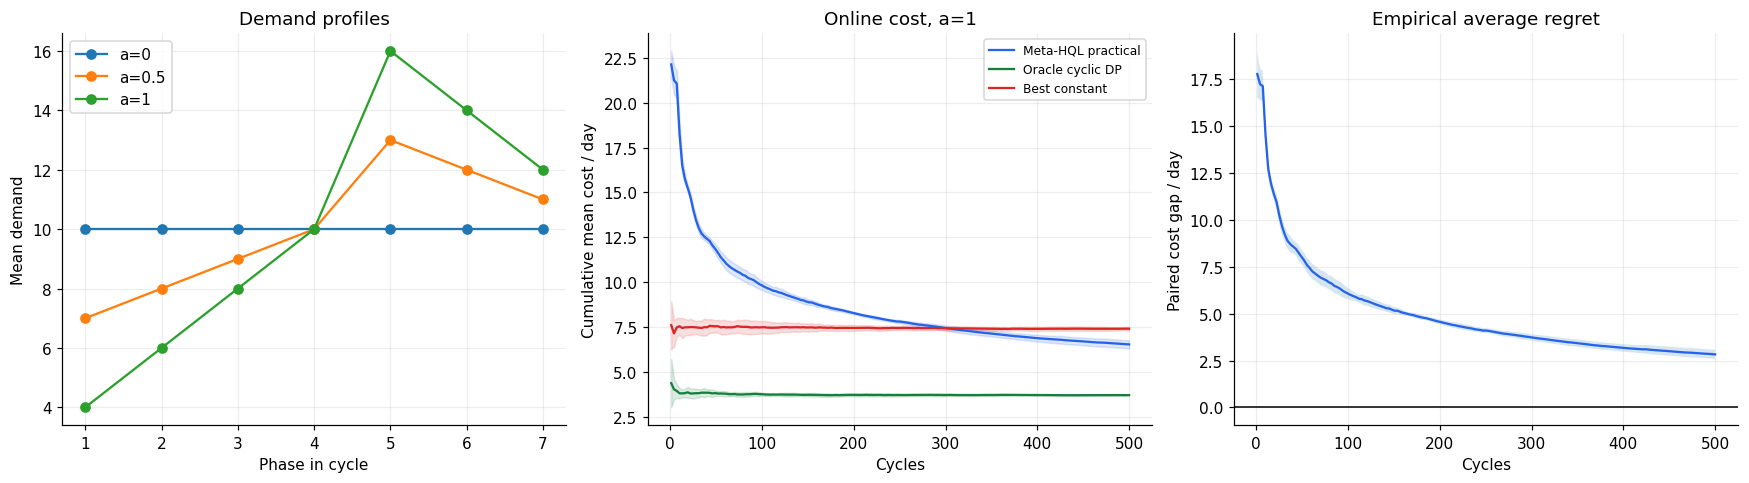

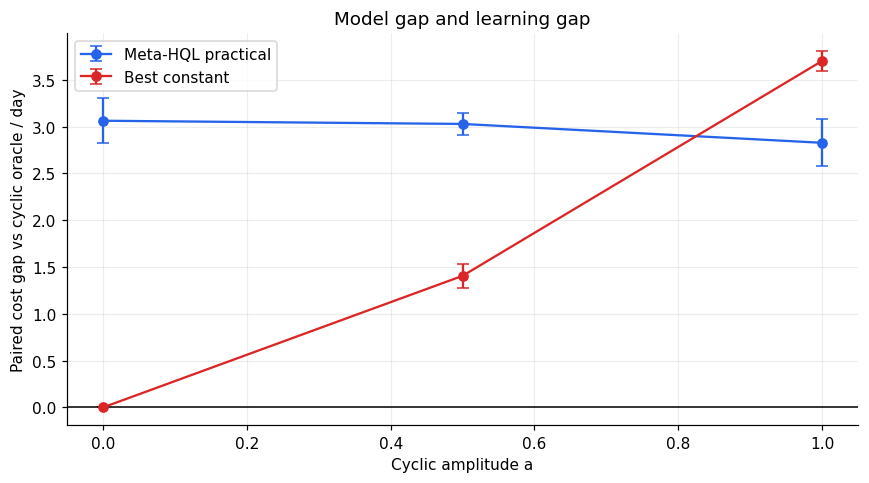

,amplitude,policy,gap,ci95
0,0.0,Meta-HQL practical,3.0636,0.2383
1,0.0,Best constant,0.0000,0.0000
2,0.5,Meta-HQL practical,3.0295,0.1165
3,0.5,Best constant,1.4060,0.1253
4,1.0,Meta-HQL practical,2.8279,0.2490
5,1.0,Best constant,3.7025,0.1067


In [5]:
AMPLITUDES = [0., .5, 1.]
panels = {a: run_online_panel(a, BASE_VOL, PENALTY) for a in AMPLITUDES}
BASE_PANEL = panels[BASE_AMPLITUDE]
tn1_runs = save_table('tn1_independent_runs', pd.concat([p['rows'] for p in panels.values()], ignore_index=True))
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for a, panel in panels.items():
    mu, sd = panel['model'].moments()
    axes[0].plot(np.arange(1, H + 1), mu, marker='o', label=f'a={a:g}')
axes[0].set(xlabel='Phase in cycle', ylabel='Mean demand', title='Demand profiles')
axes[0].legend()
checkpoints = np.unique(np.r_[np.arange(H, T + 1, max(H, (T // 150 // H) * H)), T])
curve_rows = []
for label, cost in BASE_PANEL['costs'].items():
    curves = cost.cumsum(axis=1)[:, checkpoints - 1] / checkpoints
    mean, ci = mean_ci(curves)
    axes[1].plot(checkpoints / H, mean, label=label, color=COLORS[label])
    axes[1].fill_between(checkpoints / H, mean - ci, mean + ci, alpha=.15, color=COLORS[label])
    curve_rows.extend(dict(day=int(day), policy=label, mean_daily_cost=float(m), ci95=float(c))
                      for day, m, c in zip(checkpoints, mean, ci))
axes[1].set(xlabel='Cycles', ylabel='Cumulative mean cost / day', title='Online cost, a=1')
axes[1].legend(fontsize=8)
gap = BASE_PANEL['costs'][META_LABEL] - BASE_PANEL['costs']['Oracle cyclic DP']
gap_curves = gap.cumsum(axis=1)[:, checkpoints - 1] / checkpoints
mean, ci = mean_ci(gap_curves)
axes[2].plot(checkpoints / H, mean, color=COLORS[META_LABEL])
axes[2].fill_between(checkpoints / H, mean - ci, mean + ci, alpha=.18)
axes[2].axhline(0, color='black', lw=1)
axes[2].set(xlabel='Cycles', ylabel='Paired cost gap / day', title='Empirical average regret')
save_table('tn1_learning_curves', pd.DataFrame(curve_rows))
save_table('tn1_empirical_regret_curve', pd.DataFrame(dict(day=checkpoints, gap=mean, ci95=ci)))
showfig('tn1_learning_and_demand', fig)

gap_rows = []
for a, panel in panels.items():
    for label in [META_LABEL, 'Best constant']:
        paired = (panel['costs'][label] - panel['costs']['Oracle cyclic DP']).mean(axis=1)
        mean, ci = mean_ci(paired)
        gap_rows.append(dict(amplitude=a, policy=label, gap=mean, ci95=ci))
tn1_gaps = save_table('tn1_cyclic_advantage', pd.DataFrame(gap_rows))
fig, ax = plt.subplots(figsize=(8, 4.5))
for label, g in tn1_gaps.groupby('policy', sort=False):
    ax.errorbar(g.amplitude, g.gap, yerr=g.ci95, marker='o', capsize=4, label=label, color=COLORS[label])
ax.set(xlabel='Cyclic amplitude a', ylabel='Paired cost gap vs cyclic oracle / day', title='Model gap and learning gap')
ax.axhline(0, color='black', lw=1); ax.legend()
showfig('tn1_cyclic_advantage', fig)
display(tn1_gaps.round(4))

**Khi thuyết trình:** phân biệt khoảng cách do không xét pha và khoảng cách do phải học.
Ở a=0, oracle hữu hạn có thể có hiệu ứng cuối kỳ; policy constant không nhất thiết
khớp hoàn toàn oracle. Nếu learner không vượt constant trong chân trời này, báo đúng
kết quả, kiểm tra bán kính và chân trời thay vì đổi nhãn hoặc lựa chọn seed có lợi.

## TN2. Cơ chế nội bộ và chuyển giao tồn kho (17–23 phút)

Dùng seed đầu tiên đã quy định, không chọn seed có quỹ đạo đẹp nhất. Cửa sổ hình tập trung
vào ngày chờ đầu tiên có cờ tồn kho cao; nếu không có thì dùng lần chuyển arm thứ hai.
Quỹ đạo là rời rạc,
không gọi là reflected Brownian motion. Phân biệt: switching request, ngày chờ chuyển
giao do pha/tồn kho và ngày đặt q=0 trong khi arm đang chạy. Chi phí trong ngày chờ
không đồng nhất với switching regret trong định lý. Hai cờ nguyên nhân chờ do pha và
do tồn kho có thể đồng thời đúng, không cộng hai cột ngày chờ với nhau.

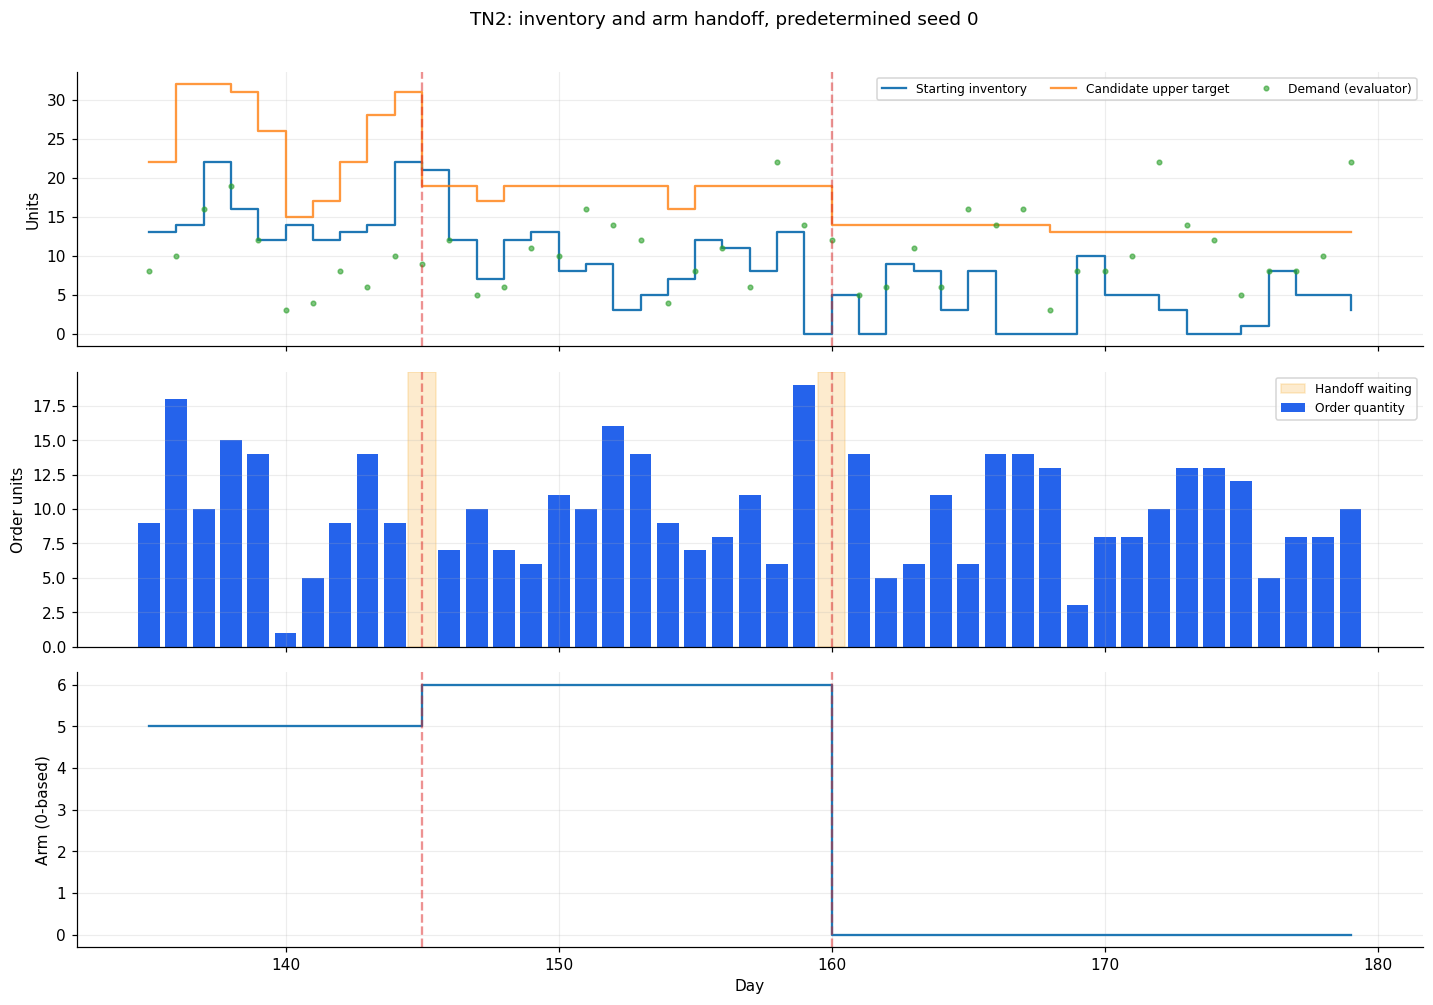

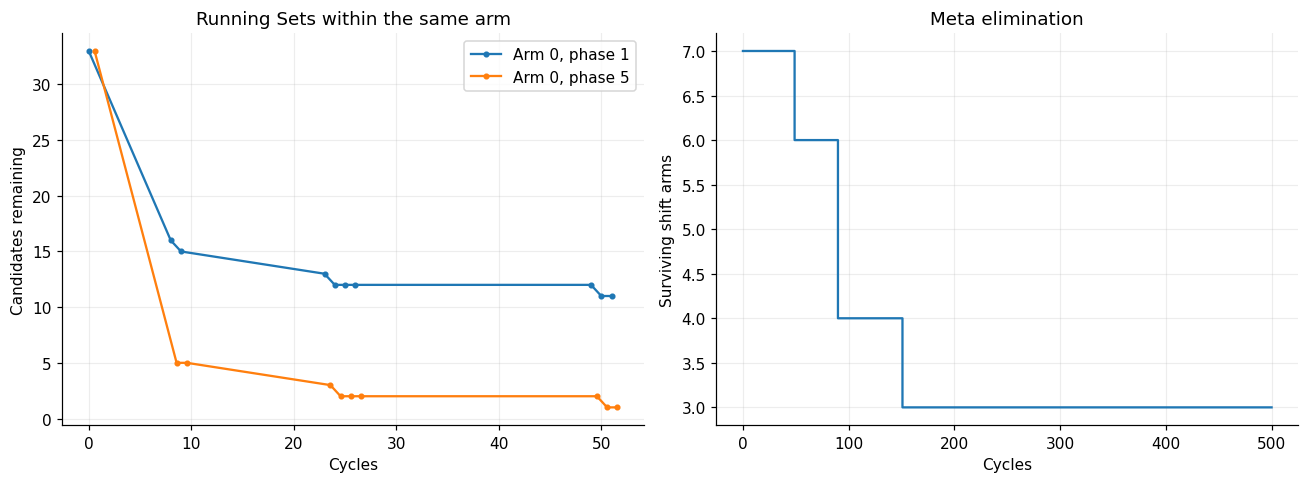

,seed,switches,waiting_days,inventory_wait_days,phase_wait_days,cost_during_wait,active_no_order_days
0,0,37,53,1,53,1223.0,82
1,1,37,53,2,53,1280.0,93
2,2,37,53,1,53,1417.0,86
3,3,39,53,1,53,1183.0,88
4,4,29,46,1,46,1003.0,85
5,5,36,53,0,53,1081.0,101


In [6]:
trace = BASE_PANEL['traces'][0]
log2 = pd.DataFrame(trace)
log2.insert(0, 'day', np.arange(T))
log2['demand_evaluator_only'] = BASE_PANEL['demands'][0]
save_table('tn2_trace_seed0', log2)
switch_days = np.flatnonzero(trace['switch'])
inventory_wait_days = np.flatnonzero(trace['inventory_wait'])
center = int(inventory_wait_days[0] if len(inventory_wait_days) else
             (switch_days[1] if len(switch_days) > 1 else (switch_days[0] if len(switch_days) else 0)))
lo, hi = max(0, center - 10), min(T, center + 35)
tt = np.arange(lo, hi)
fig, axes = plt.subplots(3, 1, figsize=(13, 9), sharex=True)
axes[0].step(tt, trace['x'][lo:hi], where='post', label='Starting inventory')
axes[0].step(tt, trace['candidate_upper'][lo:hi], where='post', label='Candidate upper target', alpha=.8)
axes[0].plot(tt, log2.demand_evaluator_only.iloc[lo:hi], '.', label='Demand (evaluator)', alpha=.6)
axes[0].legend(ncol=3, fontsize=8); axes[0].set_ylabel('Units')
axes[1].bar(tt, trace['order'][lo:hi], label='Order quantity', color='#2563eb')
for j, day in enumerate(tt[trace['waiting'][lo:hi].astype(bool)]):
    axes[1].axvspan(day - .5, day + .5, color='#f59e0b', alpha=.2,
                   label='Handoff waiting' if j == 0 else None)
axes[1].legend(fontsize=8); axes[1].set_ylabel('Order units')
axes[2].step(tt, trace['arm'][lo:hi], where='post', label='Requested shift arm')
axes[2].set(xlabel='Day', ylabel='Arm (0-based)', yticks=np.arange(H))
for ax in axes:
    for day in switch_days[(switch_days >= lo) & (switch_days < hi)]:
        ax.axvline(day, color='#dc2626', alpha=.5, linestyle='--')
fig.suptitle('TN2: inventory and arm handoff, predetermined seed 0', y=1.01)
showfig('tn2_handoff_trajectory', fig)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for h in [0, 4]:
    mask = (log2.arm == 0) & (log2.day % H == h) & (log2.waiting == 0)
    axes[0].plot(log2.loc[mask, 'day'] / H, log2.loc[mask, 'candidate_count'], marker='.', label=f'Arm 0, phase {h+1}')
axes[0].set(xlabel='Cycles', ylabel='Candidates remaining', title='Running Sets within the same arm')
axes[0].legend()
axes[1].step(log2.day / H, log2.remaining_arms, where='post')
axes[1].set(xlabel='Cycles', ylabel='Surviving shift arms', title='Meta elimination')
showfig('tn2_running_sets', fig)
rows2 = []
for seed, tr in enumerate(BASE_PANEL['traces']):
    wait = tr['waiting'].astype(bool)
    rows2.append(dict(seed=seed, switches=int(tr['switch'].sum()), waiting_days=int(wait.sum()),
                      inventory_wait_days=int(tr['inventory_wait'].sum()),
                      phase_wait_days=int(tr['phase_wait'].sum()),
                      cost_during_wait=float(tr['cost'][wait].sum()),
                      active_no_order_days=int(((tr['order']==0) & ~wait).sum())))
tn2_summary = save_table('tn2_handoff_metrics', pd.DataFrame(rows2))
display(tn2_summary)

## TN3. Biến động và đuôi chi phí (23–29 phút)

Hai phép đo có chủ đích khác nhau:
1. Nhiều lần học độc lập: quét v và p/o, lấy CI qua seeds cho chi phí trực tuyến và chờ.
2. Cố định một policy DP trung tính biết phân phối, đánh giá trên nhiều quỹ đạo 28 ngày
   độc lập: tách rủi ro vận hành khỏi quá trình học. Các CVaR này **không phải CVaR
   của Meta-HQL**. Không trộn các cửa sổ học không dừng thành mẫu đánh giá độc lập.

Online panel a=1, v=0.1, p=2 complete


Online panel a=1, v=0.35, p=2 complete


Online panel a=1, v=0.65, p=2 complete


Online panel a=1, v=0.1, p=4 complete


Online panel a=1, v=0.65, p=4 complete


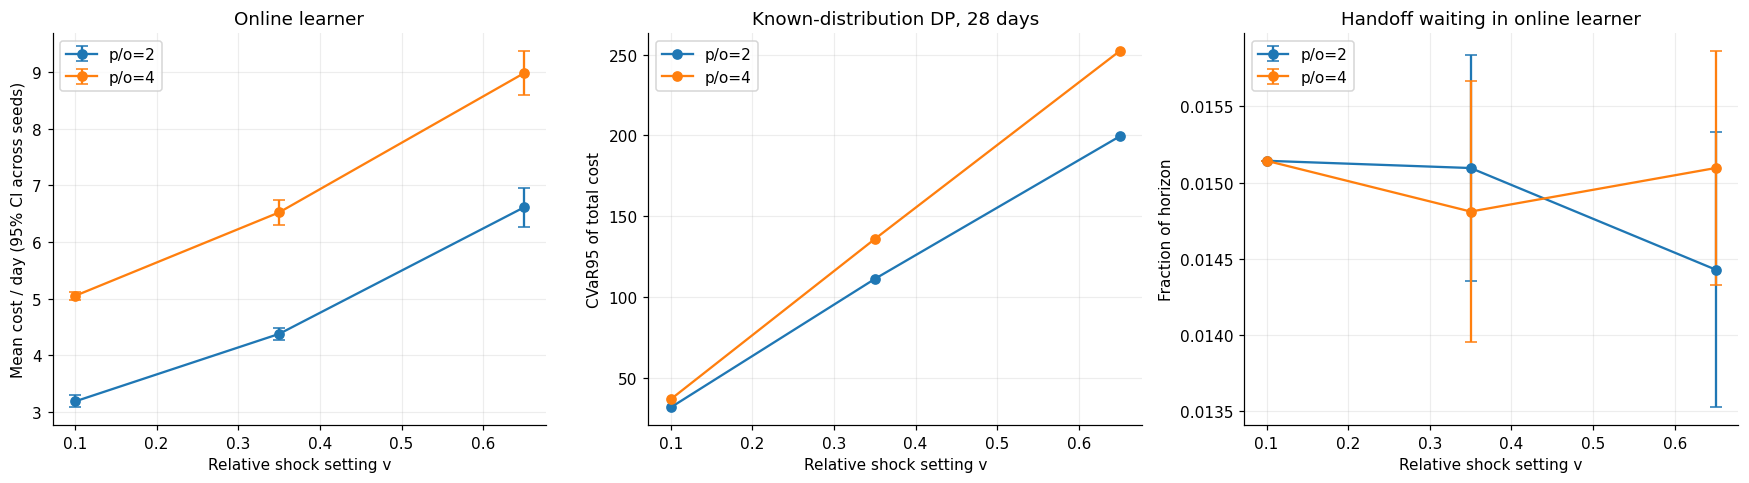

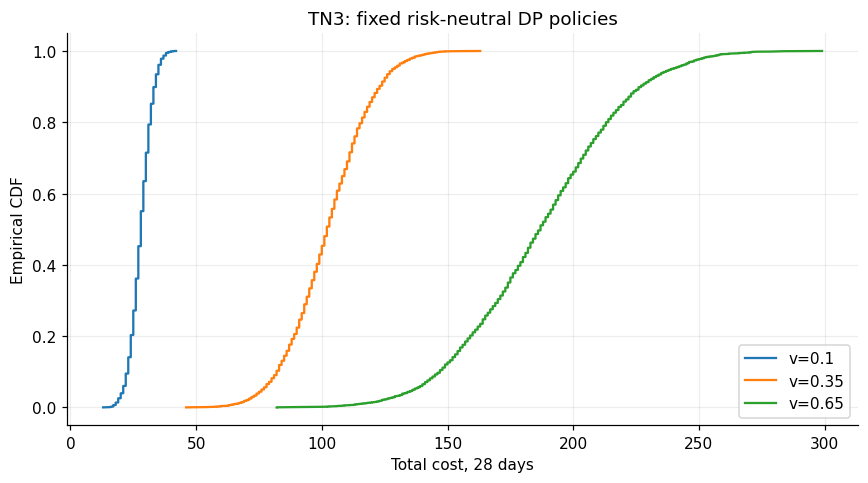

,volatility,penalty,actual_mean_sigma,policy,total_mean,cvar95,fill_rate,inventory_mean
0,0.10,2.0,0.7071,Known-distribution risk-neutral DP,20.9068,31.628,0.9753,0.2497
1,0.35,2.0,2.5254,Known-distribution risk-neutral DP,74.6226,111.200,0.9124,0.8906
2,0.65,2.0,4.5457,Known-distribution risk-neutral DP,135.6690,199.492,0.8453,1.6927
3,0.10,4.0,0.7071,Known-distribution risk-neutral DP,28.0328,36.668,1.0000,1.0012
4,0.35,4.0,2.5254,Known-distribution risk-neutral DP,102.4564,135.928,0.9920,3.3346
5,0.65,4.0,4.5457,Known-distribution risk-neutral DP,186.9338,252.336,0.9831,5.9805


In [7]:
VOLS, PENALTIES = [.1, .35, .65], [2., 4.]
vol_rows, tail_rows, tail_samples = [], [], {}
for p in PENALTIES:
    for v in VOLS:
        panel = run_online_panel(BASE_AMPLITUDE, v, p)
        model = panel['model']
        mu, sd = model.moments()
        for seed, tr in enumerate(panel['traces']):
            vol_rows.append(dict(volatility=v, penalty=p, seed=seed,
                                 actual_mean_sigma=float(sd.mean()),
                                 avg_cost=float(tr['cost'].mean()),
                                 gap_vs_oracle=float((tr['cost']-panel['costs']['Oracle cyclic DP'][seed]).mean()),
                                 switches=int(tr['switch'].sum()), waiting_fraction=float(tr['waiting'].mean())))
        dp = finite_dp(model, EVAL_HORIZON)
        d = model.draw(N_EVAL, EVAL_HORIZON, BASE_SEED + 301)
        result = evaluate_policy(model, d, policy=dp['policy'])
        totals = result['cost'].sum(axis=1)
        tail_samples[(p, v)] = totals
        tail_rows.append(dict(volatility=v, penalty=p, actual_mean_sigma=sd.mean(),
                              policy='Known-distribution risk-neutral DP', total_mean=totals.mean(),
                              cvar95=cvar(totals), fill_rate=result['fill'].mean(),
                              inventory_mean=result['inventory'].mean()))
tn3_runs = save_table('tn3_online_runs', pd.DataFrame(vol_rows))
tn3_tail = save_table('tn3_fixed_policy_tail', pd.DataFrame(tail_rows))
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for p in PENALTIES:
    g = tn3_runs[tn3_runs.penalty == p]
    stats = [(v, *mean_ci(g[g.volatility == v].avg_cost)) for v in VOLS]
    axes[0].errorbar([s[0] for s in stats], [s[1] for s in stats], yerr=[s[2] for s in stats], marker='o', capsize=4, label=f'p/o={p:g}')
    tail = tn3_tail[tn3_tail.penalty == p]
    axes[1].plot(tail.volatility, tail.cvar95, 'o-', label=f'p/o={p:g}')
    stats = [(v, *mean_ci(g[g.volatility == v].waiting_fraction)) for v in VOLS]
    axes[2].errorbar([s[0] for s in stats], [s[1] for s in stats], yerr=[s[2] for s in stats], marker='o', capsize=4, label=f'p/o={p:g}')
for ax in axes:
    ax.set_xlabel('Relative shock setting v'); ax.legend()
axes[0].set(title='Online learner', ylabel='Mean cost / day (95% CI across seeds)')
axes[1].set(title=f'Known-distribution DP, {EVAL_HORIZON} days', ylabel='CVaR95 of total cost')
axes[2].set(title='Handoff waiting in online learner', ylabel='Fraction of horizon')
showfig('tn3_volatility_sensitivity', fig)
fig, ax = plt.subplots(figsize=(8, 4.5))
for v in VOLS:
    values = np.sort(tail_samples[(PENALTY, v)])
    ax.plot(values, np.arange(1, len(values)+1) / len(values), label=f'v={v:g}')
ax.set(xlabel=f'Total cost, {EVAL_HORIZON} days', ylabel='Empirical CDF', title='TN3: fixed risk-neutral DP policies')
ax.legend(); showfig('tn3_tail_distribution', fig)
display(tn3_tail.round(4))

## TN4. Mục tiêu nhạy cảm rủi ro (29–34 phút)

Giải DP biết phân phối cho \(J_\theta=\theta^{-1}\log E[e^{\theta C}]\),
theta=0 là giới hạn trung tính. Cùng chân trời, x₀=0, terminal cost=0 và nhu cầu chặn.
Đơn vị theta là nghịch đảo đơn vị chi phí; đổi đơn vị tiền cần đổi theta tương ứng.
DP sử dụng log-sum-exp để tránh tràn số. CVaR95 chỉ dùng để **đánh giá** các policy entropic.

Không gọi đây là Distributional HQL: learner mới với phản hồi kiểm duyệt cần nghiên cứu riêng.
Pseudo-cost không bảo toàn mục tiêu rủi ro vì số hạng bỏ đi pD là ngẫu nhiên.
[Entropic risk](https://adityam.github.io/stochastic-control/risk-sensitive/risk-sensitive-utility.html),
[CVaR MDP](https://arxiv.org/abs/1506.02188).

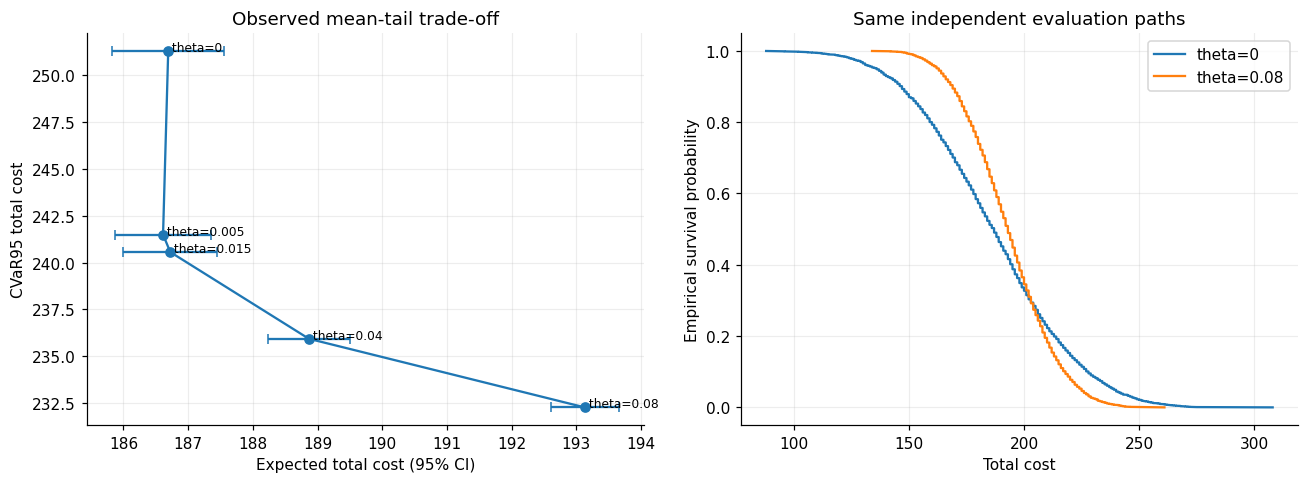

,theta,mean_total,mean_ci95,cvar95,fill_rate,mean_inventory,exact_objective,empirical_objective,initial_order
0,0.000,186.6920,0.8689,251.276,0.9830,5.9677,186.8906,186.6920,7
1,0.005,186.6122,0.7459,241.492,0.9889,6.2076,188.7102,188.4210,7
2,0.015,186.7232,0.7278,240.560,0.9908,6.2924,192.2374,191.8908,7
3,0.040,188.8668,0.6289,235.936,0.9824,6.0221,199.7833,199.2306,7
4,0.080,193.1304,0.5228,232.280,0.9668,5.5384,208.6022,207.3863,7


,theta,delta_cvar95,bootstrap_low,bootstrap_high
0,0.005,-9.784,-10.9706,-8.6841
1,0.015,-10.716,-12.2373,-9.3769
2,0.040,-15.340,-16.6631,-14.0293
3,0.080,-18.996,-20.6004,-17.4507


Monte Carlo entropic estimates can be noisy in the tail; exact DP objective is the reference.


In [8]:
RISK_MODEL = DemandModel(1., .65, HOLDING, PENALTY)
THETAS = [0., .005, .015, .04, .08]
risk_demands = RISK_MODEL.draw(N_EVAL, EVAL_HORIZON, BASE_SEED + 401)
risk_solutions, risk_totals, rows4 = {}, {}, []
for theta in THETAS:
    sol = finite_dp(RISK_MODEL, EVAL_HORIZON, theta=theta)
    ev = evaluate_policy(RISK_MODEL, risk_demands, policy=sol['policy'])
    totals = ev['cost'].sum(axis=1)
    risk_solutions[theta], risk_totals[theta] = sol, totals
    mean, ci = mean_ci(totals)
    empirical_entropic = mean if theta == 0 else (logsumexp(theta*totals) - np.log(len(totals))) / theta
    rows4.append(dict(theta=theta, mean_total=mean, mean_ci95=ci, cvar95=cvar(totals),
                      fill_rate=ev['fill'].mean(), mean_inventory=ev['inventory'].mean(),
                      exact_objective=sol['V'][0, 0], empirical_objective=empirical_entropic,
                      initial_order=sol['policy'][0, 0]))
tn4 = save_table('tn4_entropic_policies', pd.DataFrame(rows4))
diff_rows = []
for theta in THETAS[1:]:
    diff, low, high = paired_bootstrap_ci(risk_totals[theta], risk_totals[0.], cvar)
    diff_rows.append(dict(theta=theta, delta_cvar95=diff, bootstrap_low=low, bootstrap_high=high))
tn4_diff = save_table('tn4_paired_tail_differences', pd.DataFrame(diff_rows))
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].errorbar(tn4.mean_total, tn4.cvar95, xerr=tn4.mean_ci95, fmt='o-', capsize=3)
for r in rows4:
    axes[0].annotate(f" theta={r['theta']:g}", (r['mean_total'], r['cvar95']), fontsize=8)
axes[0].set(xlabel='Expected total cost (95% CI)', ylabel='CVaR95 total cost', title='Observed mean-tail trade-off')
for theta in [0., THETAS[-1]]:
    vals = np.sort(risk_totals[theta])
    axes[1].plot(vals, 1 - np.arange(1, len(vals)+1) / len(vals), label=f'theta={theta:g}')
axes[1].set(xlabel='Total cost', ylabel='Empirical survival probability', title='Same independent evaluation paths')
axes[1].legend(); showfig('tn4_risk_tradeoff', fig)
display(tn4.round(4)); display(tn4_diff.round(4))
print('Monte Carlo entropic estimates can be noisy in the tail; exact DP objective is the reference.')

**Diễn giải:** policy tối ưu entropic không nhất thiết tối ưu CVaR và không được bảo đảm
luôn tăng tồn kho. Khi theta tăng, so sánh cả mean, tail và fill rate. Nếu các điểm trùng,
đó có thể là cùng một policy trên lưới hữu hạn, không phải lỗi cần tạo nhiễu để che.

## TN5. Chi phí vốn và giá trị chờ (34–40 phút)

Giá vốn đơn vị cₚ=1000, r là lãi suất liên tục **theo năm**, Δt=1/365 năm:
\(o_{eff}=o+c_p(e^{r/365}-1)\).
Đây là proxy chi phí vốn trên **tồn kho cuối ngày**, không phải mô hình cash flow đầy đủ.
Không đồng thời cộng thêm cùng khoản opportunity cost qua một cơ chế chiết khấu khác.

Phân biệt hai bước: quét r khi K=0, sau đó thêm K để kiểm tra hiệu ứng gom đơn.
Chi phí K là phần mở rộng của nhánh lost-sales đang dùng, không gán định lý Meta-HQL cho nó.
\(\Delta_h(x)=\min_{y>x}Q_h(x,y)-Q_h(x,x)\): dương nghĩa là chờ tốt hơn.
Không gọi stopping time là free boundary hay đồng nhất bài toán với quyền chọn Mỹ.

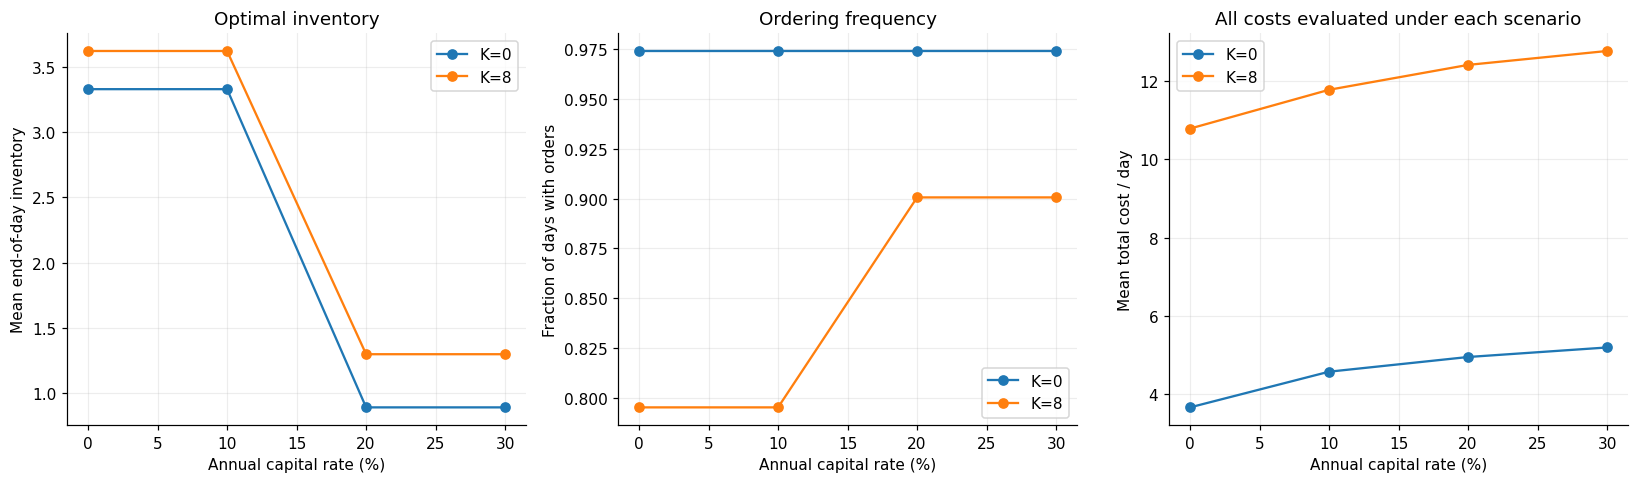

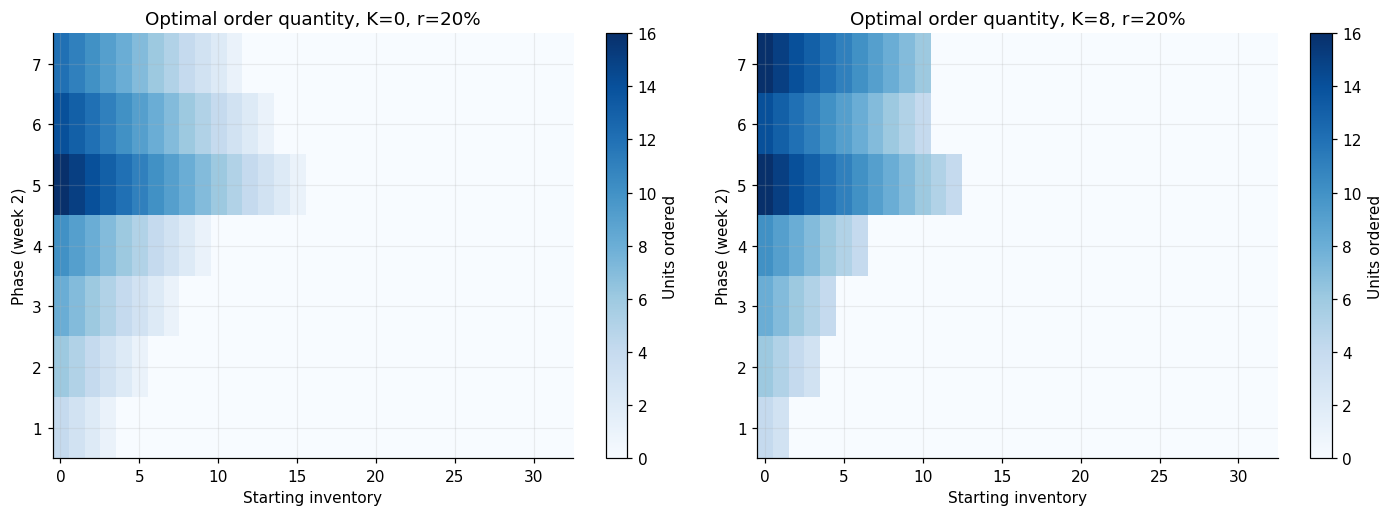

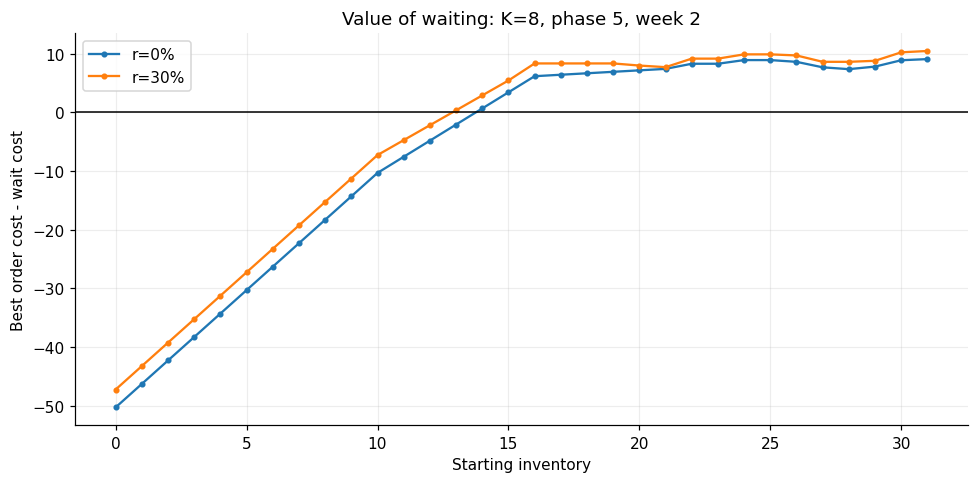

,fixed_cost,annual_rate,effective_holding,avg_cost,mean_inventory,order_frequency,fill_rate,initial_order,storage_cost_per_day,capital_cost_per_day,setup_cost_per_day,shortage_cost_per_day
0,0.0,0.0,1.0000,3.6600,3.3300,0.9741,0.9919,5,3.3300,0.0000,0.0000,0.3300
1,0.0,0.1,1.2740,4.5724,3.3300,0.9741,0.9919,5,3.3300,0.9124,0.0000,0.3300
2,0.0,0.2,1.5481,4.9481,0.8900,0.9741,0.9119,4,0.8900,0.4878,0.0000,3.5703
3,0.0,0.3,1.8223,5.1921,0.8900,0.9741,0.9119,4,0.8900,0.7318,0.0000,3.5703
4,8.0,0.0,1.0000,10.7886,3.6227,0.7953,0.9798,10,3.6227,0.0000,6.3621,0.8038
5,8.0,0.1,1.2740,11.7813,3.6227,0.7953,0.9798,10,3.6227,0.9927,6.3621,0.8038
6,8.0,0.2,1.5481,12.4175,1.2976,0.9006,0.9209,4,1.2976,0.7112,7.2051,3.2036
7,8.0,0.3,1.8223,12.7733,1.2976,0.9006,0.9209,4,1.2976,1.0670,7.2051,3.2036


Cost comparisons across rates include changed prices; also read physical inventory and order frequency.


In [9]:
CAPITAL_PRICE, DELTA_YEAR = 1000., 1 / 365
RATES, FIXED_COSTS = [0., .1, .2, .3], [0., 8.]
capital_demands = BASE.draw(N_EVAL, EVAL_HORIZON, BASE_SEED + 501)
capital_solutions, capital_rows = {}, []
for K in FIXED_COSTS:
    for rate in RATES:
        capital_unit = CAPITAL_PRICE * np.expm1(rate * DELTA_YEAR)
        effective = HOLDING + capital_unit
        sol = finite_dp(BASE, EVAL_HORIZON, effective_holding=effective, fixed_cost=K, keep_q=True)
        ev = evaluate_policy(BASE, capital_demands, policy=sol['policy'], effective_holding=effective, fixed_cost=K)
        capital_solutions[(K, rate)] = sol
        totals = ev['cost'].sum(axis=1)
        capital_rows.append(dict(fixed_cost=K, annual_rate=rate,
            effective_holding=effective, avg_cost=totals.mean()/EVAL_HORIZON,
            mean_inventory=ev['inventory'].mean(), order_frequency=(ev['orders']>0).mean(),
            fill_rate=ev['fill'].mean(), initial_order=sol['policy'][0, 0],
            storage_cost_per_day=HOLDING*ev['inventory'].mean(),
            capital_cost_per_day=capital_unit*ev['inventory'].mean(),
            setup_cost_per_day=K*(ev['orders']>0).mean(),
            shortage_cost_per_day=PENALTY*ev['lost'].mean()))
tn5 = save_table('tn5_capital_policy_metrics', pd.DataFrame(capital_rows))
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for K, group in tn5.groupby('fixed_cost'):
    label = f'K={K:g}'
    axes[0].plot(100*group.annual_rate, group.mean_inventory, 'o-', label=label)
    axes[1].plot(100*group.annual_rate, group.order_frequency, 'o-', label=label)
    axes[2].plot(100*group.annual_rate, group.avg_cost, 'o-', label=label)
for ax in axes:
    ax.set_xlabel('Annual capital rate (%)'); ax.legend()
axes[0].set(title='Optimal inventory', ylabel='Mean end-of-day inventory')
axes[1].set(title='Ordering frequency', ylabel='Fraction of days with orders')
axes[2].set(title='All costs evaluated under each scenario', ylabel='Mean total cost / day')
showfig('tn5_capital_sensitivity', fig)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
for ax, K in zip(axes, FIXED_COSTS):
    sol = capital_solutions[(K, .2)]
    times = np.arange(H, 2*H)  # second week: more than two weeks remain
    q = sol['policy'][times] - np.arange(CAP+1)[None, :]
    im = ax.imshow(q, origin='lower', aspect='auto', extent=[-.5, CAP+.5, .5, H+.5], cmap='Blues')
    ax.set(xlabel='Starting inventory', ylabel='Phase (week 2)', title=f'Optimal order quantity, K={K:g}, r=20%')
    fig.colorbar(im, ax=ax, label='Units ordered')
showfig('tn5_order_wait_map', fig)

fig, ax = plt.subplots(figsize=(9, 4.5))
delta_rows = []
for rate in [0., .3]:
    sol = capital_solutions[(8., rate)]
    t = H + 4
    qxy = sol['Q'][t]
    xs = np.arange(CAP)  # at CAP a strictly positive order is infeasible
    wait = np.diag(qxy)[:-1]
    order = np.array([qxy[x, x+1:].min() for x in xs])
    delta = order - wait
    ax.plot(xs, delta, 'o-', ms=3, label=f'r={100*rate:g}%')
    delta_rows.extend(dict(annual_rate=rate, phase=t%H+1, inventory=int(x), delta=float(z)) for x,z in zip(xs,delta))
ax.axhline(0, color='black', lw=1)
ax.set(xlabel='Starting inventory', ylabel='Best order cost - wait cost', title='Value of waiting: K=8, phase 5, week 2')
ax.legend(); showfig('tn5_value_of_waiting', fig)
save_table('tn5_action_value_gaps', pd.DataFrame(delta_rows))
display(tn5.round(4))
print('Cost comparisons across rates include changed prices; also read physical inventory and order frequency.')

## Tổng hợp để thuyết trình và kiểm tra sau chạy

Những kết luận dưới đây được tính từ kết quả thực tế, không điền sẵn một hướng biến động.
Quick mode là bản demo với ít seeds. Report mode tăng số lần học và số quỹ đạo đánh giá;
thời gian phụ thuộc máy. Không suy ra định lý regret hoặc tính mới nghiên cứu từ các hình.

Các file PNG/SVG và CSV nằm trong `outputs/gong_simchi_5_experiments/<MODE>/`.
Các ngày chờ không phải các mẫu độc lập và chi phí ngày chờ không phải switching regret.
TN4–TN5 có oracle thông tin đầy đủ, nên không dùng chúng để tuyên bố thắng learner cùng thông tin.

In [10]:
def final_checks():
    for panel in panels.values():
        for d, tr in zip(panel['demands'], panel['traces']):
            np.testing.assert_array_equal(tr['sales'], np.minimum(tr['y'], d))
            np.testing.assert_array_equal(tr['order'], tr['y'] - tr['x'])
            np.testing.assert_array_equal(tr['x'][1:], np.maximum(tr['y'][:-1]-d[:-1], 0))
            assert np.all(tr['order'][tr['waiting'].astype(bool)] == 0)
            assert len(tr['cost']) == T and np.isfinite(tr['cost']).all()
    for table in [tn1_gaps, tn3_tail, tn4, tn5]:
        assert np.isfinite(table.select_dtypes(include='number').to_numpy()).all()
    for sol in list(risk_solutions.values()) + list(capital_solutions.values()):
        assert np.all(sol['policy'] >= np.arange(CAP+1)[None, :])
        assert np.isfinite(sol['V']).all()
    # DP optimizes its own entropic objective exactly, not necessarily CVaR.
    for theta in THETAS[1:]:
        neutral_pi = risk_solutions[0.]['policy']
        own = risk_solutions[theta]
        z = np.zeros(CAP+1)
        for t in range(EVAL_HORIZON-1, -1, -1):
            y = neutral_pi[t]
            d = RISK_MODEL.support[t%H]
            nxt = np.maximum(y[:,None]-d, 0)
            cost = HOLDING*nxt + PENALTY*np.maximum(d-y[:,None], 0)
            z = logsumexp(np.log(RISK_MODEL.probabilities)+theta*(cost+z[nxt]), axis=1)/theta
        assert own['V'][0,0] <= z[0] + 1e-8
    # K=0 at r=0 exactly recovers the same finite-horizon neutral model.
    np.testing.assert_allclose(capital_solutions[(0.,0.)]['V'], finite_dp(BASE, EVAL_HORIZON)['V'])
    np.testing.assert_allclose(tn5.avg_cost,
        tn5.storage_cost_per_day + tn5.capital_cost_per_day + tn5.setup_cost_per_day + tn5.shortage_cost_per_day)
    print('PASS: physical feasibility, censoring, no disposal, DP risk optimality and capital zero limit.')

final_checks()
base_runs = BASE_PANEL['rows']
summary_rows = []
for label, g in base_runs.groupby('policy', sort=False):
    mean, ci = mean_ci(g.avg_cost)
    summary_rows.append(dict(policy=label, mean_daily_cost=mean, ci95_across_training_seeds=ci,
                             mean_fill_rate=g.fill_rate.mean()))
summary = save_table('summary_tn1_base', pd.DataFrame(summary_rows))
display(summary.round(4))
learning_gap = tn1_gaps[(tn1_gaps.amplitude==1)&(tn1_gaps.policy==META_LABEL)].iloc[0]
model_gap = tn1_gaps[(tn1_gaps.amplitude==1)&(tn1_gaps.policy=='Best constant')].iloc[0]
display(Markdown(f"""
### Các số có thể đưa vào slide kết luận
- Khoảng cách constant–oracle tại a=1: **{model_gap.gap:.3f} ± {model_gap.ci95:.3f}** chi phí/ngày (95% CI).
- Khoảng cách learner–oracle tại a=1: **{learning_gap.gap:.3f} ± {learning_gap.ci95:.3f}** chi phí/ngày.
- Đã xuất **{len(FIGURES)} hình** và **{len(TABLES)} bảng**.
- Cấu hình: **{MODE}**, {N_SEEDS} seeds học, {N_CYCLES} chu kỳ, {N_EVAL} quỹ đạo đánh giá độc lập.
- Thời gian tính đến đây: **{time.perf_counter()-START:.1f} giây** trên máy đang chạy.

Đọc TN3 để xác định hướng thay đổi theo biến động; đọc CI ghép cặp TN4 trước khi nói
CVaR giảm; đọc TN5 để phân biệt tăng giá vốn với thay đổi hành vi tồn kho.
"""))
manifest = dict(configuration=CONFIG, figures=FIGURES, tables=list(TABLES),
                elapsed_seconds=time.perf_counter()-START,
                implementation='finite-grid practical Meta-HQL variant; known-distribution exact DP extensions')
(OUT/'manifest.json').write_text(json.dumps(manifest, indent=2), encoding='utf-8')

PASS: physical feasibility, censoring, no disposal, DP risk optimality and capital zero limit.


,policy,mean_daily_cost,ci95_across_training_seeds,mean_fill_rate
0,Meta-HQL practical,6.5241,0.2258,0.9832
1,Oracle cyclic DP,3.6962,0.0308,0.9890
2,Best constant,7.3987,0.0941,0.9320



### Các số có thể đưa vào slide kết luận
- Khoảng cách constant–oracle tại a=1: **3.702 ± 0.107** chi phí/ngày (95% CI).
- Khoảng cách learner–oracle tại a=1: **2.828 ± 0.249** chi phí/ngày.
- Đã xuất **10 hình** và **13 bảng**.
- Cấu hình: **quick**, 6 seeds học, 500 chu kỳ, 5000 quỹ đạo đánh giá độc lập.
- Thời gian tính đến đây: **32.8 giây** trên máy đang chạy.

Đọc TN3 để xác định hướng thay đổi theo biến động; đọc CI ghép cặp TN4 trước khi nói
CVaR giảm; đọc TN5 để phân biệt tăng giá vốn với thay đổi hành vi tồn kho.


1232

## Tài liệu và giới hạn sử dụng kết quả

1. Gong & Simchi-Levi, *Bandits atop Reinforcement Learning: Tackling Online Inventory Models
   with Cyclic Demands*, Management Science 70(9), 6139–6157 (2024).
   https://doi.org/10.1287/mnsc.2023.4947
2. Mahajan, *Risk Sensitive Utility*: https://adityam.github.io/stochastic-control/risk-sensitive/risk-sensitive-utility.html
3. Chow et al., *Risk-Sensitive and Robust Decision-Making: a CVaR Optimization Approach*:
   https://arxiv.org/abs/1506.02188
4. Dai & Yao, *Brownian Inventory Models with Convex Holding Cost, Part 1*:
   https://doi.org/10.1287/11-SSY041

Notebook không chứng minh độ mới nghiên cứu, không ước lượng tài chính từ dữ liệu thị trường,
không chứng minh giới hạn diffusion hay chặn regret. Mô hình có chân trời hữu hạn và terminal
cost bằng 0: policy gần cuối kỳ có thể khác policy tuần ở giữa. Các con số là theo đơn vị
chi phí giả định đã công bố trong cấu hình. Giới hạn của nguyên lưới và bán kính thực hành
phải đi kèm khi trình bày kết quả.